# 08a — EDA phần A: Ở ĐÂU (người phụ trách: Lucknow/Jaipur)

**Câu hỏi nghiên cứu chung**

> **Ô nhiễm không khí nặng (AQI từ 201 trở lên) tập trung ở thành phố nào và vào mùa nào trong 8 thành phố Ấn Độ giai đoạn 2015–2020, để cơ quan môi trường và người dân biết nên ưu tiên cảnh báo sức khỏe và giảm phát thải ở đâu, lúc nào?**


**Quy ước chung** (chi tiết ở `08_eda.ipynb`): so sánh giữa thành phố chỉ dùng `win` (khoảng chung); "nặng" = AQI >= 201 trên số ngày **có AQI**;
mùa: Đông (12-2), Hè (3-5), Mưa (6-9), Sau mưa (10-11); chỉ viết "có liên quan", **không** viết "gây ra".
Hàm dùng chung nằm ở `src/eda_utils.py` (không sửa nếu chưa báo nhóm).

**Làm việc nhóm:** chỉ sửa notebook **này** và chỉ lưu hình có tên của phần mình (`eda_<số>_...png`). `git pull` trước khi push.

## Việc cần làm
1. Bảng thống kê 4 họ theo thành phố (hàm đã có, hãy đọc và giải thích từng cột bằng lời).
2. **Biểu đồ 1**: % ngày AQI >= 201 theo thành phố (cột ngang, sắp giảm dần, từ 0, tô nhấn thành phố cao nhất).
3. **Biểu đồ 5**: phân phối AQI theo thành phố (boxplot, sắp theo trung vị) để thấy phân tán và hình dạng.

## Lưu ý đã phát hiện khi kiểm tra
- Các thành phố có tỉ lệ gần nhau **đổi thứ hạng khi bỏ ngẫu nhiên 10% dòng** (xem bảng kiểm tra độ nhạy ở `08_eda.ipynb`): Lucknow và Gurugram, Amritsar và Jaipur, Bengaluru và Hyderabad. Vì vậy hãy **nhóm các thành phố** (ví dụ nhóm rất nặng, nhóm trung bình, nhóm gần như không) thay vì xếp hạng từng thành phố.
- Bảng `skew` > 0 nghĩa là phân phối lệch phải (nhiều ngày thấp, ít ngày rất cao); giải thích điều này bằng lời vì nó quyết định nên dùng **trung vị** hay trung bình.

**Câu vấn đáp phải trả lời được**: confounder nào có thể giải thích khác biệt giữa các thành phố? (gợi ý: số và vị trí trạm đo, quy mô đô thị, địa lý, thời tiết; dữ liệu này **không** có thời tiết và không có vị trí trạm.) Biểu đồ này có thể đánh lừa người đọc vội ở chỗ nào?

## Chuẩn biểu đồ (W7), tick đủ trước khi push

- [ ] Tiêu đề là **kết luận có con số** (không phải "AQI theo thành phố")
- [ ] Trục có **nhãn và đơn vị**
- [ ] Biểu đồ cột **bắt đầu từ 0**, sắp theo giá trị (không theo bảng chữ cái)
- [ ] **Một** màu nhấn cho điều muốn người đọc thấy, còn lại màu trung tính
- [ ] Ghi nhãn trực tiếp, bỏ legend nếu chỉ có một nhóm
- [ ] Không dùng biểu đồ tròn, 3D, trục kép; không dùng chỉ đỏ-xanh lá để phân biệt
- [ ] Thử chuyển sang thang xám vẫn đọc được
- [ ] Chú thích có cỡ mẫu và ngày dữ liệu (hàm `finish_chart` đã làm sẵn)

## 0. Setup

In [1]:
import sys, os
sys.path.append(os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from eda_utils import (CITIES, USABLE, SEASON_ORDER, ACCENT, NEUTRAL,
                       vn, load, poor_share, four_families, finish_chart, save_fig, set_style)

set_style()
eda, win, START, END = load()      # eda: toàn bộ 2015-2020 | win: khoảng chung của 8 thành phố (dùng khi so sánh giữa thành phố)

Toàn bộ: 14.056 dòng, 01/01/2015 - 01/07/2020
Khoảng chung (biến win): 14/06/2017 - 01/07/2020, 8.912 dòng; 8.734 ngày có AQI


## A1. Bảng 4 họ thống kê (AQI, khoảng chung)

In [2]:
stats_city = four_families(win, "AQI", "City").sort_values("median", ascending=False)
stats_city

,n,mean,median,std,iqr,skew,spearman_PM2.5
City,,,,,,,
Delhi,1105,225.38,205.0,121.09,192.00,0.66,0.96
Lucknow,1111,206.98,188.0,112.69,211.00,0.43,0.96
Gurugram,1070,211.55,187.5,112.45,182.00,0.79,0.94
Jaipur,1093,133.52,122.0,54.09,63.00,1.33,0.88
Amritsar,1029,122.45,104.0,76.84,64.00,2.94,0.81
Hyderabad,1108,92.56,89.0,35.22,56.25,0.38,0.93
Chennai,1110,98.94,87.0,39.71,37.00,2.19,0.69
Bengaluru,1108,86.58,81.0,27.57,37.00,1.65,0.80


### Đọc bảng A1 bằng lời

Bảng tính trên **AQI hằng ngày trong khoảng chung** (14/06/2017 – 01/07/2020, 1.114 ngày), sắp theo trung vị giảm dần.

| Cột | Họ thống kê | Nghĩa là gì | Đọc từ bảng này |
|---|---|---|---|
| `n` | cỡ mẫu | Số ngày có AQI | Từ 1.029 (Amritsar) đến 1.111 (Lucknow) trên 1.114 ngày. Amritsar thiếu 85 ngày (7,6%), Gurugram thiếu 44 ngày (khoảng 4%), nên hai thành phố này kém chắc hơn. |
| `mean` | vị trí | Trung bình cộng | Delhi 225, Gurugram 212, Lucknow 207 cao nhất; Bengaluru 87 thấp nhất. Bị kéo lên bởi vài ngày rất cao. |
| `median` | vị trí | Giá trị ở giữa: một nửa số ngày thấp hơn nó | Delhi 205, Lucknow 188, Gurugram 188 (187,5), Jaipur 122, Amritsar 104, Hyderabad 89, Chennai 87, Bengaluru 81. Ít bị ảnh hưởng bởi ngày cực đoan. |
| `std` | phân tán | Độ lệch chuẩn, độ tản quanh trung bình | Lớn nhất ở Delhi (121), nhỏ nhất ở Bengaluru (28). Nhạy với ngày cực đoan. |
| `iqr` | phân tán | Q3 trừ Q1: bề rộng của 50% số ngày ở giữa | Lucknow 211 là lớn nhất, kế đó Delhi 192 và Gurugram 182. Jaipur 63 và Amritsar 64 hẹp hơn nhiều. Chennai và Bengaluru chỉ 37. Không bị ngày cực đoan làm sai lệch. |
| `skew` | hình dạng | Độ lệch. 0 là đối xứng, lớn hơn 0 là đuôi bên phải dài (nhiều ngày thấp, ít ngày rất cao) | Cả 8 thành phố đều lớn hơn 0 (từ 0,38 đến 2,94). Amritsar (2,94) và Chennai (2,19) lệch nhiều nhất; Hyderabad (0,38) và Lucknow (0,43) gần đối xứng nhất. |
| `spearman_PM2.5` | quan hệ | Tương quan **hạng** giữa AQI và PM2.5 cùng ngày (không đòi hỏi quan hệ đường thẳng) | Từ 0,69 (Chennai) đến 0,96 (Delhi, Lucknow). PM2.5 là một thành phần để tính AQI nên tương quan cao là điều **đã nằm sẵn trong cách tính**, không phải phát hiện độc lập. Chennai thấp nhất, có thể vì ở đó chất khác chi phối AQI nhiều ngày hơn (giả thuyết, chưa kiểm tra). |

**Vì sao ưu tiên trung vị và IQR?** Cả 8 thành phố đều có `skew` > 0 và `mean` > `median`. Phân phối lệch phải thì vài ngày rất cao kéo trung bình và độ lệch chuẩn lên. Trung vị mô tả "ngày điển hình", IQR mô tả độ rộng của phần lớn các ngày, nên hai số này đáng tin hơn khi so sánh các thành phố. `mean` và `std` chỉ để tham khảo.


## A2. Biểu đồ 1: % ngày AQI >= 201 theo thành phố

,pct_poor,n_days
City,,
Hyderabad,0.1,1108
Bengaluru,0.2,1108
Chennai,3.1,1110
Jaipur,11.1,1093
Amritsar,11.4,1029
Gurugram,46.3,1070
Lucknow,46.4,1111
Delhi,51.0,1105


Đã lưu reports/figures/eda_01_poor_share_city.png


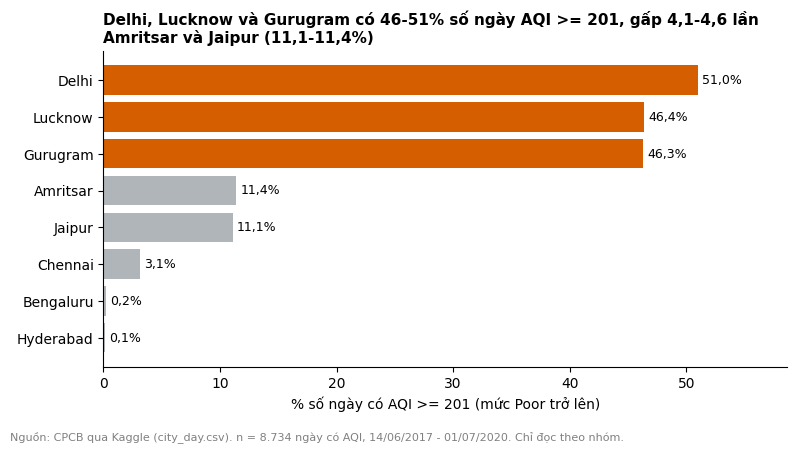

In [3]:
share_city = poor_share(win, "City").sort_values("pct_poor")     # tăng dần để cột lớn nằm trên cùng
display(share_city)

# Nhấn NHÓM 3 thành phố cao nhất bằng MỘT màu (vì Lucknow và Gurugram đổi thứ hạng khi bỏ 10% dòng, xem 08_eda.ipynb)
top3 = list(share_city.index[-3:])
hi = share_city.pct_poor.loc[top3]
lo = share_city.pct_poor.loc[["Amritsar", "Jaipur"]]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(share_city.index.astype(str), share_city.pct_poor.values,
               color=[ACCENT if c in top3 else NEUTRAL for c in share_city.index])
ax.bar_label(bars, labels=[vn(v, 1) + "%" for v in share_city.pct_poor.values], padding=3, fontsize=9)
ax.set_xlim(0, share_city.pct_poor.max() * 1.15)
ax.set_xlabel("% số ngày có AQI >= 201 (mức Poor trở lên)"); ax.set_ylabel("")
finish_chart(fig, ax,
             f"Delhi, Lucknow và Gurugram có {vn(hi.min())}-{vn(hi.max())}% số ngày AQI >= 201, "
             f"gấp {vn(hi.min() / lo.max(), 1)}-{vn(hi.max() / lo.min(), 1)} lần Amritsar và Jaipur "
             f"({vn(lo.min(), 1)}-{vn(lo.max(), 1)}%)", win,
             note="Chỉ đọc theo nhóm.")
save_fig(fig, "01_poor_share_city")
plt.show()


## A3. Biểu đồ 5: phân phối AQI theo thành phố

Đã lưu reports/figures/eda_05_aqi_distribution.png


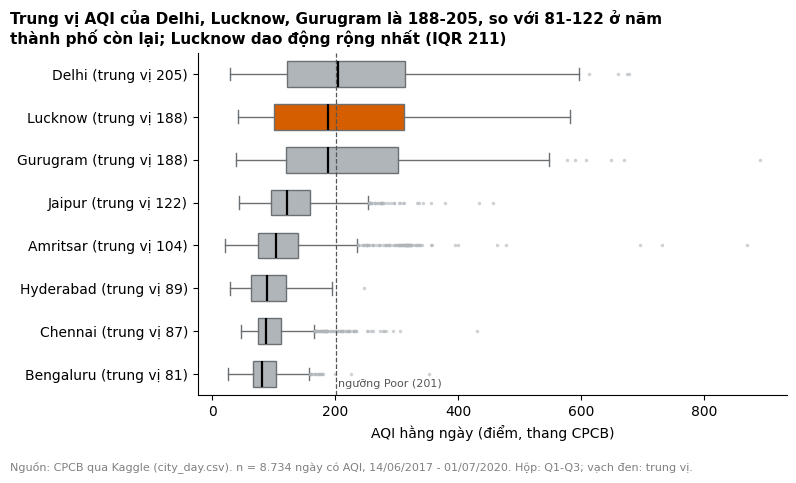

In [4]:
d = win.dropna(subset=["AQI"])
med = d.groupby("City", observed=True).AQI.median()
order = med.sort_values(ascending=False).index.tolist()           # trung vị giảm dần: cao nhất ở trên cùng
data = [d.loc[d.City == c, "AQI"].values for c in order]

# Nhấn Lucknow vì IQR lớn nhất trong 8 thành phố (xem bảng A1)
focus = stats_city["iqr"].idxmax()

fig, ax = plt.subplots(figsize=(8, 4.8))
bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.6, showfliers=True,
                flierprops=dict(marker="o", markersize=2.5, markerfacecolor=NEUTRAL, markeredgecolor="none", alpha=0.6),
                medianprops=dict(color="black", linewidth=1.6),
                whiskerprops=dict(color="#6B7075"), capprops=dict(color="#6B7075"))
for patch, c in zip(bp["boxes"], order):
    patch.set_facecolor(ACCENT if c == focus else NEUTRAL)
    patch.set_edgecolor("#6B7075")
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels([f"{c} (trung vị {vn(med[c])})" for c in order])   # ghi nhãn trực tiếp
ax.invert_yaxis()                                                      # vị trí 1 ở trên cùng
ax.axvline(201, color="#555555", linestyle="--", linewidth=0.9)
ax.text(205, 0.02, "ngưỡng Poor (201)", transform=ax.get_xaxis_transform(), va="bottom", fontsize=8, color="#555555")
ax.set_xlabel("AQI hằng ngày (điểm, thang CPCB)"); ax.set_ylabel("")

top3_med = med.loc[["Delhi", "Lucknow", "Gurugram"]]
rest_med = med.drop(["Delhi", "Lucknow", "Gurugram"])
finish_chart(fig, ax,
             f"Trung vị AQI của Delhi, Lucknow, Gurugram là {vn(top3_med.min())}-{vn(top3_med.max())}, "
             f"so với {vn(rest_med.min())}-{vn(rest_med.max())} ở năm thành phố còn lại; "
             f"{focus} dao động rộng nhất (IQR {vn(stats_city.loc[focus, 'iqr'])})", win,
             note="Hộp: Q1-Q3; vạch đen: trung vị.")
# nhãn trục dài đẩy khung vẽ sang phải: dời tiêu đề về mép trái của hình để không bị cắt
fig.canvas.draw()
pos = ax.get_position()
ax.set_title(ax.get_title(loc="left"), loc="left", x=(0.01 - pos.x0) / pos.width, fontsize=11, fontweight="bold")
save_fig(fig, "05_aqi_distribution")
plt.show()


## Phát hiện của phần A (người ghép báo cáo sẽ gom bảng này vào mục 5)

Mỗi phát hiện phải gắn **một biểu đồ** (không có biểu đồ thì chỉ là ý kiến), kèm confounder và hạn chế.

| # | Phát hiện (có con số) | Biểu đồ | Confounder có thể | Hạn chế |
|---|---|---|---|---|
| A1 | Trong khoảng chung 14/06/2017 – 01/07/2020, Delhi (51,0%), Lucknow (46,4%) và Gurugram (46,3%) có khoảng một nửa số ngày AQI >= 201, gấp 4,1-4,6 lần Amritsar (11,4%) và Jaipur (11,1%). Chennai chỉ 3,1%, Bengaluru 0,2% và Hyderabad 0,1% gần như không có ngày nặng. | 1 | Số và vị trí trạm đo (mỗi thành phố chỉ có một chuỗi, có thể là trạm gần đường lớn hay khu công nghiệp); quy mô đô thị và giao thông; địa lý và thời tiết (dữ liệu **không** có thời tiết và vị trí trạm). | Khoảng chung chỉ gần 3 năm, có cả giai đoạn phong tỏa COVID-19 (từ 25/3/2020). Lucknow và Gurugram, Amritsar và Jaipur, Bengaluru và Hyderabad đổi thứ hạng khi bỏ ngẫu nhiên 10% dòng, nên chỉ đọc theo **nhóm**, không xếp hạng. Amritsar thiếu 85 ngày AQI, Gurugram thiếu 44 ngày; nếu ngày thiếu rơi vào mùa nặng hoặc nhẹ thì tỉ lệ lệch theo. Chỉ có tương quan (có liên quan), không kết luận nguyên nhân. |
| A2 | Phân phối AQI của ba thành phố nhóm đầu nằm cao hơn hẳn: trung vị 188-205 so với 81-122 ở năm thành phố còn lại. Lucknow dao động rộng nhất (IQR 211, Delhi 192, Gurugram 182) so với Jaipur 63 và Amritsar 64. Trong khoảng chung, trung vị mùa của Lucknow đi từ 91 (mùa mưa) đến 325 (mùa đông) nên ngày "điển hình" phụ thuộc rất nhiều vào mùa. Cả 8 thành phố đều lệch phải (skew 0,38-2,94), nên trung vị phù hợp hơn trung bình. | 5 | Mùa vụ (biểu đồ này gộp mọi mùa nên độ rộng một phần phản ánh chênh lệch mùa chứ không chỉ độ ổn định); số và vị trí trạm; số ngày thiếu mỗi thành phố khác nhau. | Boxplot không cho biết **khi nào** nặng (phần B của nhóm). `skew` rất nhạy với vài ngày cực đoan, ví dụ Amritsar 2,94 do một số ít ngày rất cao. Có ngày AQI vượt 500 (tối đa 891 ở Gurugram) trong khi thang CPCB dừng ở 500; nhóm chưa đối chiếu nguồn gốc. Trung vị Lucknow và Gurugram (188) rất sát ngưỡng 201, nên % ngày nặng nhạy với việc chọn ngưỡng. |

**Trước khi push:** Restart & Run All không lỗi; đã tick checklist biểu đồ; đã `git pull`.

## Trả lời vấn đáp (viết bằng lời của mình)

**Confounder nào có thể giải thích khác biệt giữa các thành phố?**
Số và vị trí trạm đo (đây là điểm mạnh nhất vì mỗi thành phố chỉ có một chuỗi), quy mô đô thị và mật độ giao thông, địa lý, thời tiết và gió. Bộ dữ liệu này không có thời tiết và không có vị trí trạm, nên nhóm không thể loại trừ các yếu tố đó. Vì vậy báo cáo chỉ viết "có liên quan" và không viết "gây ra".

**Biểu đồ 1 có thể đánh lừa người đọc vội ở chỗ nào?**
(1) Ngưỡng 201 là một đường cắt cứng: ngày AQI 195 và ngày AQI 205 gần như giống nhau nhưng một ngày được tính là nặng, một ngày thì không. Trung vị Lucknow và Gurugram (188) đang nằm sát ngưỡng này. (2) Cột dài hơn không có nghĩa thành phố "ô nhiễm hơn" nếu trạm đo đặt ở chỗ khác nhau. (3) Thứ hạng giữa các thành phố có tỉ lệ gần nhau không ổn định, nên không nên nói "Lucknow cao hơn Gurugram". (4) Tỉ lệ tính trên số ngày **có** AQI, mỗi thành phố một mẫu số khác nhau. (5) Khoảng chung chỉ gần 3 năm và có phong tỏa COVID-19.

**Biểu đồ 5 có thể đánh lừa người đọc vội ở chỗ nào?**
Boxplot gộp mọi mùa, nên hộp rộng như Lucknow có thể bị hiểu là "thất thường" trong khi phần lớn là chênh lệch giữa mùa đông và mùa mưa. Các chấm ở ngoài râu chỉ là ngày xa phần giữa, chưa chắc là lỗi hay ngoại lai thật. Ngoài ra, hình dạng của hộp không nói gì về nguyên nhân.
